# Customer Segmentation using K-Means
**Internship project (Intermediate) | CognoRise InfoTech**

**Dataset:** Mall Customer Segmentation Data (Kaggle), file `Mall_Customers.csv`
**Goal:** Group mall customers by age, income and spending behaviour, then suggest a marketing action for each group.

**How to use:** keep `Mall_Customers.csv` in the same folder, run top to bottom, and replace each *Interpretation* line with what you see.

In [41]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)

## 1. Load and inspect

In [42]:
df = pd.read_csv("Mall_Customers.csv")
# Some versions of the file call the gender column "Genre"; standardise names
df = df.rename(columns={
    "Genre": "Gender",
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "SpendingScore",
})
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Income,SpendingScore
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [43]:
df.info()
print()
print("Missing values:\n", df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate CustomerIDs:", df["CustomerID"].duplicated().sum())
df.describe().round(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     200 non-null    int64 
 1   Gender         200 non-null    object
 2   Age            200 non-null    int64 
 3   Income         200 non-null    int64 
 4   SpendingScore  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:
 CustomerID       0
Gender           0
Age              0
Income           0
SpendingScore    0
dtype: int64

Duplicate rows: 0
Duplicate CustomerIDs: 0


,CustomerID,Age,Income,SpendingScore
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


## 2. Data cleaning
This dataset is already clean, so the steps are checks: remove duplicates, confirm sensible ranges, and check for outliers.

In [44]:
df = df.drop_duplicates().reset_index(drop=True)
df["Gender"] = df["Gender"].str.strip().str.title()

# Range checks
assert df["Age"].between(10, 100).all(), "Unexpected ages"
assert df["SpendingScore"].between(1, 100).all(), "Spending score out of range"
assert (df["Income"] > 0).all(), "Non-positive income"

# Outlier check with the IQR rule
for col in ["Age", "Income", "SpendingScore"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_out} outlier(s) by the IQR rule")

Age: 0 outlier(s) by the IQR rule
Income: 2 outlier(s) by the IQR rule
SpendingScore: 0 outlier(s) by the IQR rule


*Note:* outliers are real customers here (for example a high earner), so they are kept, not removed.

## 3. Exploratory data analysis

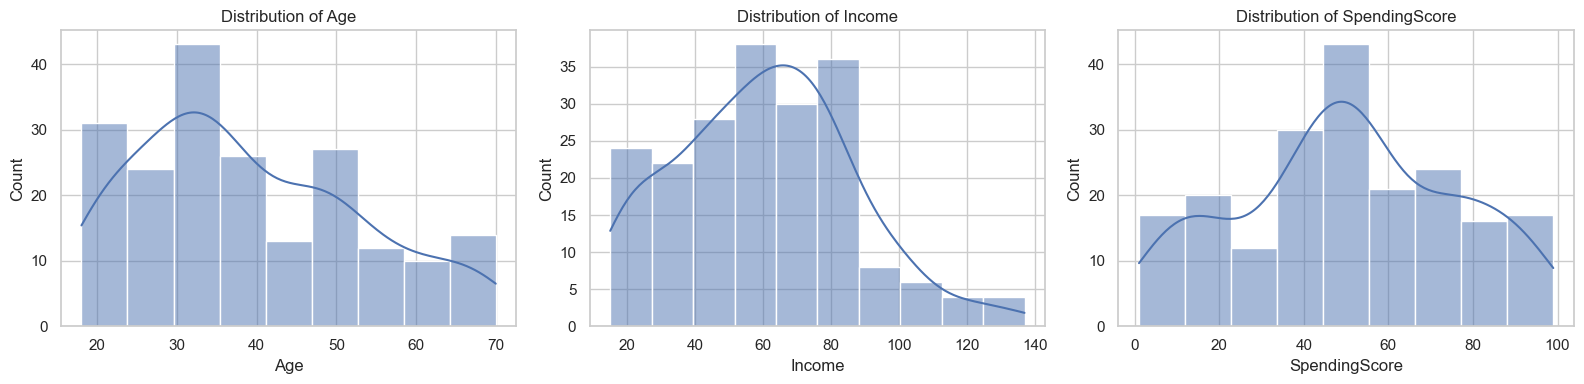

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Age", "Income", "SpendingScore"]):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig("outputs/01_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation – Data Distribution

The age distribution shows that most customers are between their twenties and forties. Annual income is mainly concentrated between 40k and 80k. Spending Scores are distributed across different levels, with many customers having scores around 40–60. This indicates that the dataset contains customers with varied demographic and spending characteristics.


Gender
Female    0.56
Male      0.44
Name: proportion, dtype: float64


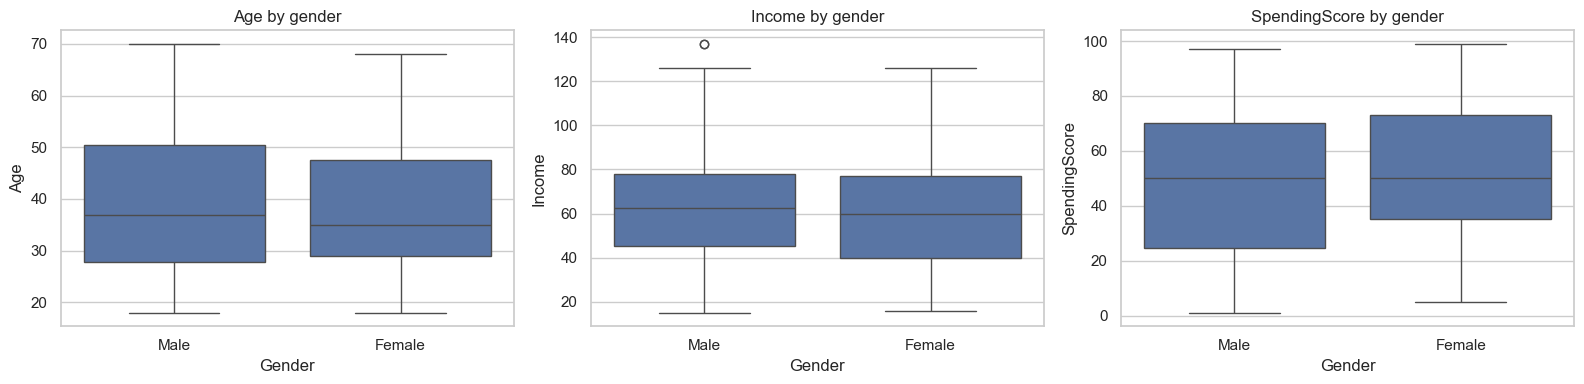

         Age  Income  SpendingScore
Gender                             
Female  38.1    59.2           51.5
Male    39.8    62.2           48.5


In [46]:
print(df["Gender"].value_counts(normalize=True).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Age", "Income", "SpendingScore"]):
    sns.boxplot(data=df, x="Gender", y=col, ax=ax)
    ax.set_title(f"{col} by gender")
plt.tight_layout()
plt.savefig("outputs/02_by_gender.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("Gender")[["Age", "Income", "SpendingScore"]].mean().round(1))

### Interpretation – Gender Analysis

The dataset consists of approximately 56% female customers and 44% male customers. The average age and income are slightly higher among male customers, while female customers have a slightly higher average Spending Score. However, the differences are relatively small, suggesting broadly similar spending patterns across genders.

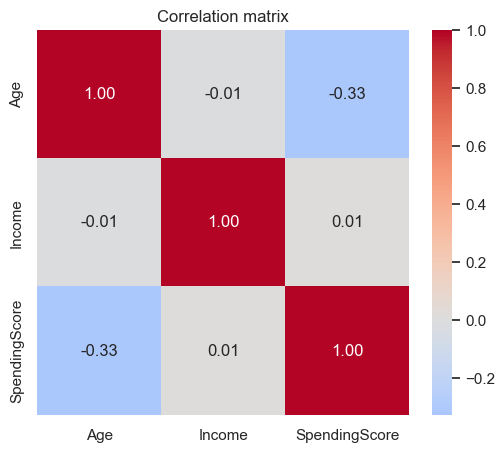

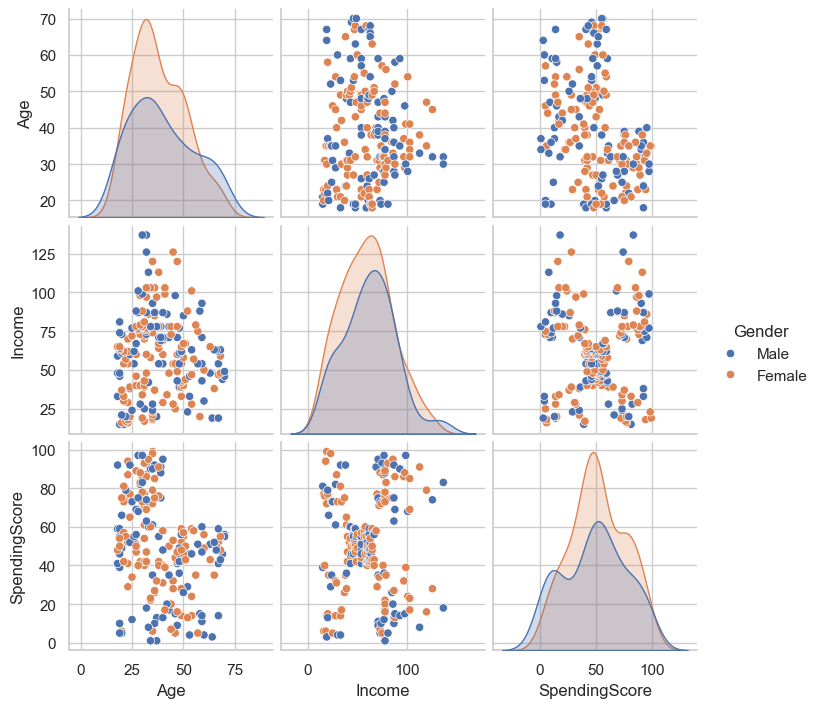

In [47]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[["Age", "Income", "SpendingScore"]].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation matrix")
plt.savefig("outputs/03_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

sns.pairplot(df[["Age", "Income", "SpendingScore", "Gender"]], hue="Gender", height=2.4)
plt.savefig("outputs/04_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

### Interpretation – Correlation Analysis

The correlation matrix shows that Age and Spending Score have a moderate negative correlation (-0.33), indicating that older customers tend to have lower spending scores. Income and Spending Score have almost no linear correlation (0.01), suggesting that income alone does not explain customer spending behaviour. Similarly, Age and Income are almost uncorrelated (-0.01). The pairplot also shows different customer patterns, supporting the need to consider multiple features for customer segmentation.

## 4. Feature selection and scaling
Clustering uses distance, so features on larger scales (income) would dominate. We standardise them first.
We cluster on **Age, Income and Spending Score**. Gender is left out of the model (it adds little and is binary), but used later to describe each segment.

In [48]:
features = ["Age", "Income", "SpendingScore"]
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled mean:", X_scaled.mean(axis=0).round(2), "| std:", X_scaled.std(axis=0).round(2))

Scaled mean: [-0. -0. -0.] | std: [1. 1. 1.]


## 5. Choosing the number of clusters (k)

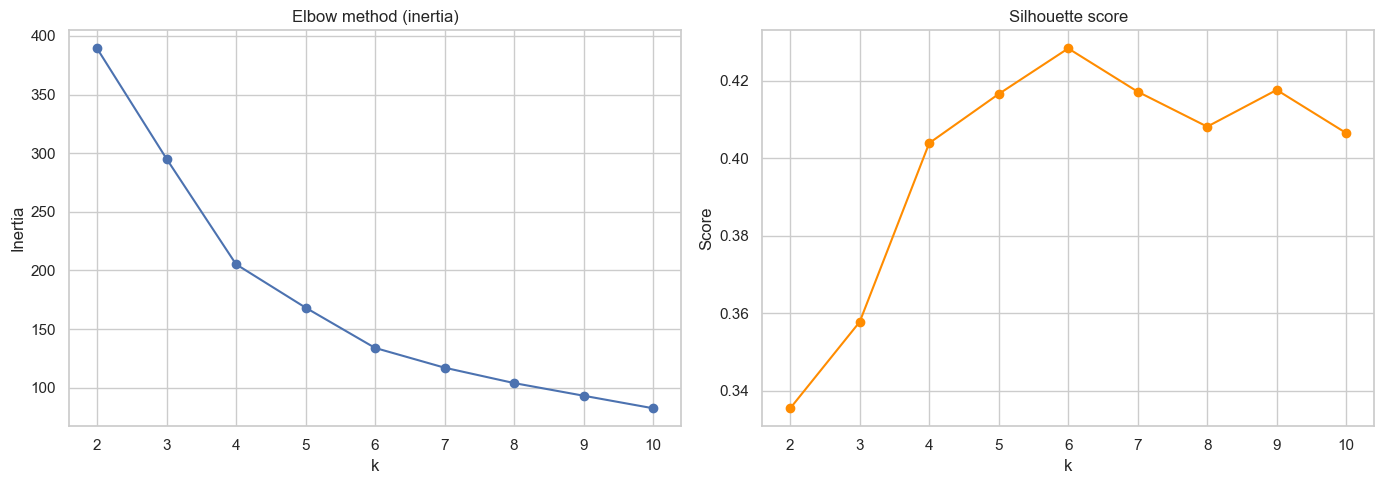

,k,inertia,silhouette
0,2,389.386,0.335
1,3,295.212,0.358
2,4,205.225,0.404
3,5,168.248,0.417
4,6,133.868,0.428
5,7,117.012,0.417
6,8,103.873,0.408
7,9,93.093,0.418
8,10,82.385,0.407


In [49]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(ks), inertia, marker="o")
axes[0].set_title("Elbow method (inertia)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(ks), sil, marker="o", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Score")
plt.tight_layout()
plt.savefig("outputs/05_elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

results = pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil}).round(3)
results

### Interpretation – Choosing the Number of Clusters

The Elbow Method shows a noticeable reduction in inertia up to K = 4, after which the decrease becomes more gradual. The Silhouette Score is highest at K = 6, with a value of 0.428. Based on the Silhouette Score and the elbow plot, six clusters were selected for the final K-Means model.

In [50]:
# Pick k. Default: the k with the best silhouette score. Override if the elbow clearly says otherwise.
best_k = int(results.loc[results["silhouette"].idxmax(), "k"])
print("k with the highest silhouette:", best_k)

K = best_k   # <- change this number if you choose a different k after reading the plots
print("Using k =", K)

k with the highest silhouette: 6
Using k = 6


## 6. Final model

In [51]:
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
df["Cluster"] = kmeans.labels_
print("Silhouette score:", round(silhouette_score(X_scaled, df["Cluster"]), 3))
print()
print(df["Cluster"].value_counts().sort_index())

Silhouette score: 0.427

Cluster
0    33
1    45
2    24
3    39
4    38
5    21
Name: count, dtype: int64


## 7. Visualising the clusters

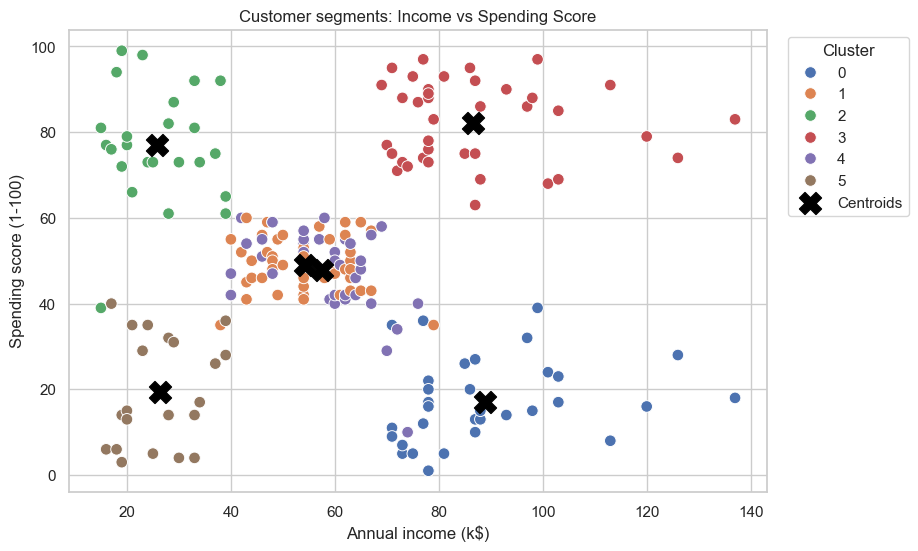

In [52]:
palette = sns.color_palette("deep", K)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Income", y="SpendingScore", hue="Cluster", palette=palette, s=70)
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 1], centers[:, 2], c="black", marker="X", s=250, label="Centroids")
plt.title("Customer segments: Income vs Spending Score")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score (1-100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig("outputs/06_clusters_income_spending.png", dpi=150, bbox_inches="tight")
plt.show()

Variance explained by 2 components: 0.78


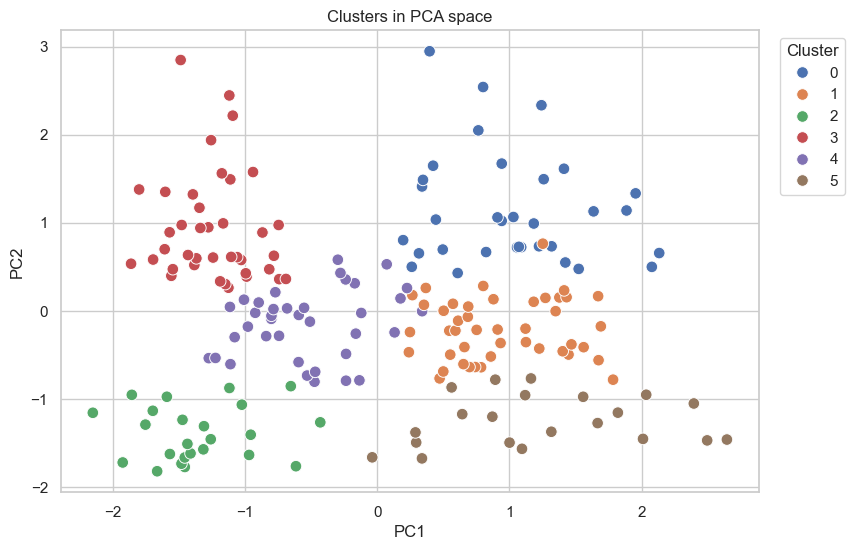

In [53]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
print("Variance explained by 2 components:", pca.explained_variance_ratio_.sum().round(2))

plt.figure(figsize=(9, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["Cluster"], palette=palette, s=70)
plt.title("Clusters in PCA space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig("outputs/07_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

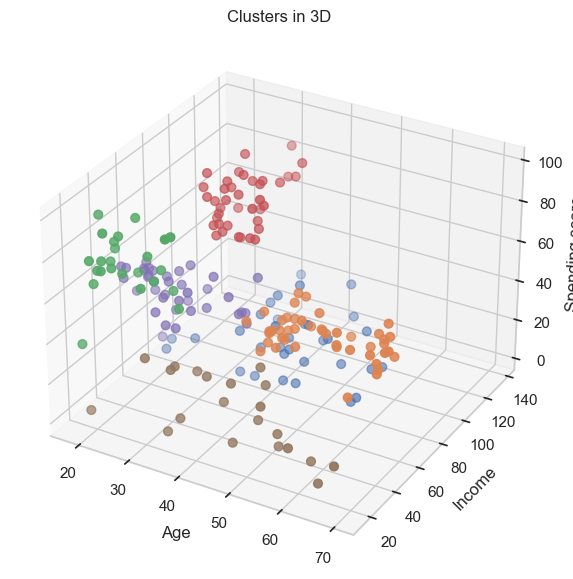

In [54]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(df["Age"], df["Income"], df["SpendingScore"], c=[palette[c] for c in df["Cluster"]], s=40)
ax.set_xlabel("Age")
ax.set_ylabel("Income")
ax.set_zlabel("Spending score")
ax.set_title("Clusters in 3D")
plt.savefig("outputs/08_clusters_3d.png", dpi=150, bbox_inches="tight")
plt.show()

*Interpretation:* (are the clusters well separated? which pairs of features separate them best?)

## 8. Segment profiles

In [55]:
profile = df.groupby("Cluster").agg(
    customers=("CustomerID", "count"),
    avg_age=("Age", "mean"),
    avg_income=("Income", "mean"),
    avg_spending=("SpendingScore", "mean"),
    pct_female=("Gender", lambda s: (s == "Female").mean() * 100),
).round(1)
profile["share_%"] = (profile["customers"] / profile["customers"].sum() * 100).round(1)
profile

,customers,avg_age,avg_income,avg_spending,pct_female,share_%
Cluster,,,,,,
0,33,41.9,88.9,17.0,42.4,16.5
1,45,56.3,54.3,49.1,57.8,22.5
2,24,25.2,25.8,76.9,58.3,12.0
3,39,32.7,86.5,82.1,53.8,19.5
4,38,26.7,57.6,47.8,63.2,19.0
5,21,45.5,26.3,19.4,61.9,10.5


In [56]:
# Auto-suggest a label from income and spending relative to the overall median
inc_med, spend_med = df["Income"].median(), df["SpendingScore"].median()

def label(row):
    hi_inc = row["avg_income"] >= inc_med
    hi_sp = row["avg_spending"] >= spend_med
    if hi_inc and hi_sp:
        return "High income, high spending (VIP)"
    if hi_inc and not hi_sp:
        return "High income, low spending (untapped)"
    if not hi_inc and hi_sp:
        return "Low income, high spending (enthusiasts)"
    return "Low income, low spending (budget)"

profile["suggested_label"] = profile.apply(label, axis=1)
profile[["customers", "avg_age", "avg_income", "avg_spending", "suggested_label"]]

,customers,avg_age,avg_income,avg_spending,suggested_label
Cluster,,,,,
0,33,41.9,88.9,17.0,"High income, low spending (untapped)"
1,45,56.3,54.3,49.1,"Low income, low spending (budget)"
2,24,25.2,25.8,76.9,"Low income, high spending (enthusiasts)"
3,39,32.7,86.5,82.1,"High income, high spending (VIP)"
4,38,26.7,57.6,47.8,"Low income, low spending (budget)"
5,21,45.5,26.3,19.4,"Low income, low spending (budget)"


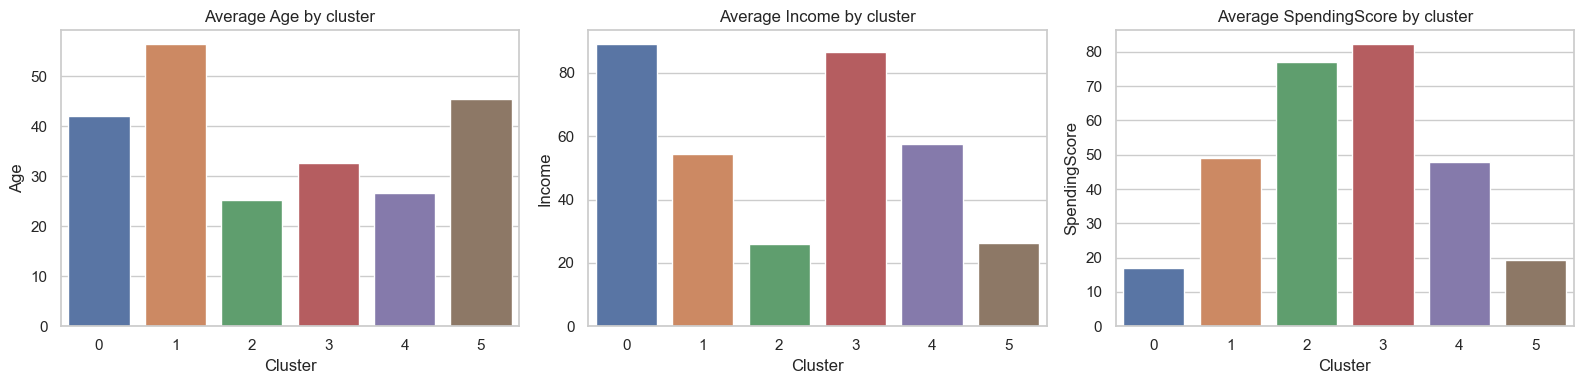

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Age", "Income", "SpendingScore"]):
    sns.barplot(data=df, x="Cluster", y=col, palette=palette, ax=ax, errorbar=None)
    ax.set_title(f"Average {col} by cluster")
plt.tight_layout()
plt.savefig("outputs/09_cluster_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

df.to_csv("outputs/customers_with_segments.csv", index=False)

## 9. Segment names and marketing recommendations
*The labels above are automatic suggestions. Check them against the charts, rename them if needed, and fill in the table with your real numbers.*
 
## 9. Segment Names and Marketing Recommendations

| Cluster | Segment Name | Customer Profile | Recommended Marketing Action |
|---|---|---|---|
| 0 | Affluent Low-Spending Customers | Middle-aged customers with high income but low spending. | Offer personalised recommendations, exclusive products and loyalty incentives. |
| 1 | Older Moderate-Spending Customers | Older customers with moderate income and spending. | Provide loyalty rewards and targeted promotions. |
| 2 | Young High-Spending Customers | Young customers with low income but high spending. | Introduce affordable trendy products, discounts and social media promotions. |
| 3 | Premium VIP Customers | Young-to-middle-aged customers with high income and high spending. | Offer premium services, VIP memberships and exclusive deals. |
| 4 | Young Moderate-Spending Customers | Young customers with moderate income and spending. | Use seasonal offers and personalised product recommendations. |
| 5 | Low-Income Low-Spending Customers | Middle-aged customers with low income and low spending. | Focus on budget-friendly products and seasonal discounts. |


### Interpretation – Final Customer Segments

The K-Means model identified six distinct customer segments based on age, annual income and spending score. These segments represent different customer behaviours, including affluent low-spending customers, moderate-spending customers, young high-spending customers and premium VIP customers. Each segment requires a different marketing strategy, such as personalised recommendations, loyalty rewards, discounts and premium services. These insights can help businesses develop targeted marketing campaigns and improve customer engagement.



## 10. Limitations
- The dataset has only about 200 customers and 3 numeric features, and the spending score is a mall-assigned value, not real transactions.
- K-Means assumes roughly round, similar-sized clusters and is sensitive to scaling and the random starting points (we fix `random_state` and use `n_init`).
- Segments describe this snapshot; they should be re-checked as behaviour changes.